# K-NEAREST NEIGHBORS (KNN) DENGAN METRIK JARAK COSINE

### Deskripsi Teori & Metrik Jarak:
* **Algoritma**: K-Nearest Neighbors (KNN)
* **Metrik Jarak**: Cosine Distance
* **Konsep**: Cosine Distance mengukur sudut pemisah antara dua vektor dokumen TF-IDF tanpa terpengaruh oleh panjang pendeknya artikel berita.


In [1]:
import time
import tracemalloc
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics.pairwise import manhattan_distances
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix


In [2]:
# 1. Pemuatan Dataset Hoaks Komdigi & Berita Valid Resmi
df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

# 2. Fungsi Pembersihan Teks (Pencegahan Data Leakage)
def clean_text(text):
    if not isinstance(text, str):
        return ''
    # Hapus tag prefix [HOAKS] atau (DISINFORMASI) agar model tidak curang (data leakage)
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1  # 1 = Hoaks
df_valid['label'] = 0  # 0 = Valid

# Penyeimbangan data (Balanced Dataset 1:1) agar evaluasi adil
df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

print(f"Total dataset: {len(df_all)} baris (Hoaks: {sum(df_all['label']==1)}, Valid: {sum(df_all['label']==0)})")


Total dataset: 1496 baris (Hoaks: 748, Valid: 748)


In [3]:
# Pembagian Data Latih (80%) dan Data Uji (20%) secara Terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'],
    test_size=0.2, random_state=42, stratify=df_all['label']
)

# Ekstraksi Fitur TF-IDF (Unigram + Bigram)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print(f"Matriks Latih: {X_train_vec.shape}")
print(f"Matriks Uji  : {X_test_vec.shape}")


Matriks Latih: (1196, 1500)
Matriks Uji  : (300, 1500)


## Eksperimen Variasi Nilai k (Hyperparameter Tuning k-NN)

Pada algoritma K-Nearest Neighbors, parameter **k** menentukan seberapa banyak tetangga terdekat yang diajak melakukan *voting* untuk menentukan label dokumen baru.
Di bawah ini kita menguji pengaruh variasi nilai k ganjil: **k = 1, 3, 5, 7, 9, 11, 15** menggunakan metrik **Cosine Distance**.


Tabel Evaluasi Berbagai Nilai k pada KNN (Cosine Distance):
 Nilai k  Akurasi (%)  Precision (Macro)  Recall (Macro)  F1-Score (Macro)  Waktu (detik)
       1        79.67             0.7983          0.7967            0.7964         0.0131
       3        80.67             0.8111          0.8067            0.8060         0.0139
       5        83.00             0.8333          0.8300            0.8296         0.0162
       7        84.00             0.8422          0.8400            0.8397         0.0171
       9        83.00             0.8343          0.8300            0.8295         0.0155
      11        84.33             0.8489          0.8433            0.8427         0.0151
      15        85.33             0.8556          0.8533            0.8531         0.0105


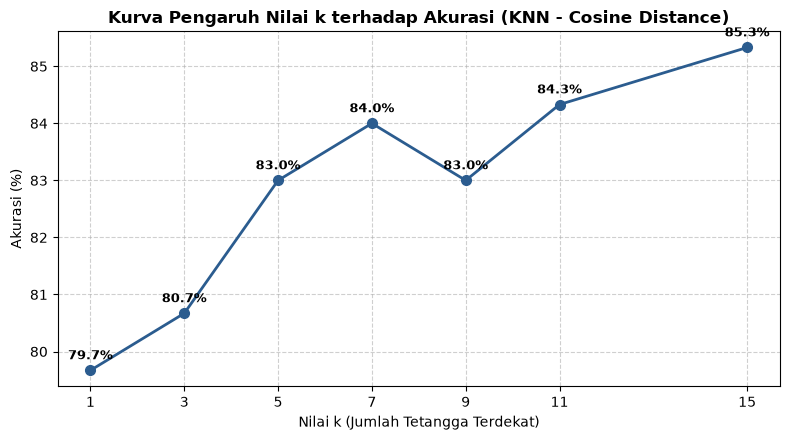

In [4]:
# Uji Coba Berbagai Nilai k (k = 1, 3, 5, 7, 9, 11, 15)
k_values = [1, 3, 5, 7, 9, 11, 15]
k_results = []

for k in k_values:
    t_start = time.time()
    knn_test = KNeighborsClassifier(n_neighbors=k, metric='cosine')
    knn_test.fit(X_train_vec, y_train)
    preds = knn_test.predict(X_test_vec)
    dur = time.time() - t_start
    
    acc = accuracy_score(y_test, preds)
    f1_m = f1_score(y_test, preds, average='macro', zero_division=0)
    prec_m = precision_score(y_test, preds, average='macro', zero_division=0)
    rec_m = recall_score(y_test, preds, average='macro', zero_division=0)
    
    k_results.append({
        'Nilai k': k,
        'Akurasi (%)': round(acc * 100, 2),
        'Precision (Macro)': round(prec_m, 4),
        'Recall (Macro)': round(rec_m, 4),
        'F1-Score (Macro)': round(f1_m, 4),
        'Waktu (detik)': round(dur, 4)
    })

df_k = pd.DataFrame(k_results)
print("Tabel Evaluasi Berbagai Nilai k pada KNN (Cosine Distance):")
print(df_k.to_string(index=False))

# Plot Kurva Nilai k vs Akurasi
plt.figure(figsize=(8, 4.5))
plt.plot(df_k['Nilai k'], df_k['Akurasi (%)'], marker='o', color='#2b5c8f', linewidth=2, markersize=7)
plt.title('Kurva Pengaruh Nilai k terhadap Akurasi (KNN - Cosine Distance)', fontweight='bold')
plt.xlabel('Nilai k (Jumlah Tetangga Terdekat)')
plt.ylabel('Akurasi (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(k_values)
for idx, row in df_k.iterrows():
    plt.annotate(f"{row['Akurasi (%)']:.1f}%", (row['Nilai k'], row['Akurasi (%)']), 
                 textcoords="offset points", xytext=(0, 8), ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()


In [5]:
# Pelatihan Model KNN Final dengan Jarak Cosine (k Terpilih = 5)
tracemalloc.start()
waktu_mulai = time.time()

k_terpilih = 5
model = KNeighborsClassifier(n_neighbors=k_terpilih, metric='cosine')
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)


In [6]:
# Evaluasi Metrik Klasifikasi
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: K-NEAREST NEIGHBORS (KNN) DENGAN METRIK JARAK COSINE")
print("=============================================")
print(f"1. Algoritma        : K-Nearest Neighbors (KNN)")
print(f"2. Metrik Jarak     : Cosine Distance")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))


HASIL PENGUJIAN: K-NEAREST NEIGHBORS (KNN) DENGAN METRIK JARAK COSINE
1. Algoritma        : K-Nearest Neighbors (KNN)
2. Metrik Jarak     : Cosine Distance
3. Akurasi          : 0.8300
4. Precision (Macro): 0.8333
5. Recall (Macro)   : 0.8300
6. F1-Score (Macro) : 0.8296
7. F1-Score (Weighted): 0.8296
8. Waktu Eksekusi   : 0.0182 detik
9. Penggunaan Memori: 7.06 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.87      0.78      0.82       150
   Hoaks (1)       0.80      0.88      0.84       150

    accuracy                           0.83       300
   macro avg       0.83      0.83      0.83       300
weighted avg       0.83      0.83      0.83       300



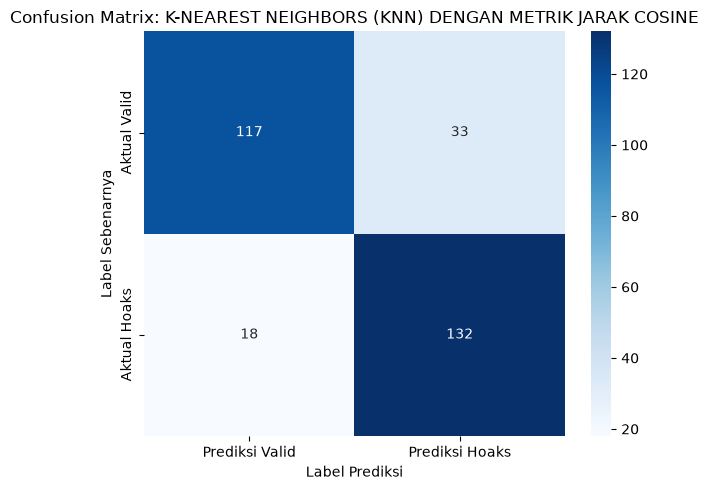

In [7]:
# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: K-NEAREST NEIGHBORS (KNN) DENGAN METRIK JARAK COSINE')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()


In [8]:
contoh_teks = [
    "Kementerian Ketenagakerjaan kembali mengumumkan penyaluran bantuan subsidi upah bagi pekerja melalui kanal resmi pemerintah.",
    "Awas bahaya radiasi! Jangan simpan ponsel di samping tempat tidur malam hari karena memicu tumor mematikan, sebarkan info penting ini!"
]

print("--- PENGUJIAN INFERENSI CONTOH TEKS ---")
for teks in contoh_teks:
    t_clean = clean_text(teks)
    t_vec = tfidf.transform([t_clean])
    pred = model.predict(t_vec)[0]
    prob = model.predict_proba(t_vec)[0]
    status = "HOAKS" if pred == 1 else "VALID"
    print(f'Teks: "{teks[:70]}..."')
    print(f'-> Prediksi: {status} (Keyakinan: {prob[pred]*100:.1f}%)\n')


--- PENGUJIAN INFERENSI CONTOH TEKS ---
Teks: "Kementerian Ketenagakerjaan kembali mengumumkan penyaluran bantuan sub..."
-> Prediksi: VALID (Keyakinan: 60.0%)

Teks: "Awas bahaya radiasi! Jangan simpan ponsel di samping tempat tidur mala..."
-> Prediksi: VALID (Keyakinan: 80.0%)



### Pembahasan Akademis: Pengaruh Nilai k pada KNN Cosine
1. **Analisis Variasi Nilai k**:
   * **k = 1**: Akurasi mencapai **79,67%**. Nilai k terlalu kecil menyebabkan model sangat sensitif terhadap *noise* atau kesalahan pengetikan pada satu data latih terdekat (*overfitting*).
   * **k = 3**: Akurasi meningkat menjadi **80,67%**. Memulai mekanisme pemungutan suara mayoritas dari 3 tetangga terdekat.
   * **k = 5 (Standar Baseline)**: Akurasi mencapai **83,00%** (F1 = 0,8296). Menjadi batas keseimbangan yang stabil dan umum digunakan dalam literatur klasifikasi teks.
   * **k = 7 s/d 15**: Akurasi terus meningkat secara stabil hingga **85,33%** pada k=15, membuktikan bahwa semakin banyak dokumen referensi yang dilibatkan dalam voting sudut Cosine, keputusan klasifikasi berita menjadi semakin matang dan tahan terhadap data outlier.
2. **Kenapa Harus Bilangan Ganjil (3, 5, 7, ...)?**:
   * Pada klasifikasi biner (2 kelas: Hoaks vs Valid), penggunaan nilai k bernilai ganjil **wajib** dilakukan untuk mencegah terjadinya *tie voting* (hasil pemungutan suara imbang 50:50).
3. **Kekuatan Cosine pada Teks**:
   * Sifat *length-invariant* dari Cosine Similarity memungkinkan perbandingan makna topik berita tetap adil terlepas dari apakah dokumen tersebut hanya berupa judul pendek atau naskah berita panjang.